# SPITE and the Strip (Closed-form equations)

In [3]:
import numpy as np
def quasistatic_hammerstad_jensen(er, width,height):
    """
    Quasi-static microstrip effective permittivity and characteristic impedance.

    S. J. Orfanidis, Electromagnetic Waves and Antennas,
    Rutgers University, 2016, Sec. 11.3, p. 543.

    E. Hammerstad and O. Jensen, "Accurate Models for Microstrip
    Computer-Aided Design," IEEE MTT-S International Microwave
    Symposium Digest, pp. 407-409, 1980.
    DOI: 10.1109/MWSYM.1980.1124303
    """
    f = np.atleast_1d(np.asarray(f, dtype=float))
    er = np.asarray(er, dtype=float)

    if er.ndim != 0:
        raise ValueError("er must be a scalar. Frequency-dependent substrate permittivity is not supported in this version.")
    w = width
    h = height
    u = w/h

    a = 1 + np.log((u**4 + (u / 52)**2)/(u**4 + 0.432))/49 + np.log(1 + (u / 18.1)**3)/18.7
    b = 0.564*((er-0.9)/(er+3))**0.053

    eeff = (er+1)/2 + (er-1)/2*(1+10/u)**(-a*b)

    fu = 6 + (2 * np.pi - 6) * np.exp(-(30.666 / u)**0.7528)
    eta0 = 376.730313668

    Zc = (eta0/(2 * np.pi * np.sqrt(eeff))*np.log(fu/u + np.sqrt(1+ 4/u**2)))


    return eeff, Zc

def eeff_kirschning_jansen(f, er, width, height ):
    """
    Frequency-dependent effective permittivity of a microstrip line.

    M. Kirschning and R. H. Jansen, "Accurate Model for Effective
    Dielectric Constant of Microstrip with Validity up to
    Millimetre-Wave Frequencies," Electronics Letters,
    vol. 18, no. 6, pp. 272-273, March 1982.
    DOI: 10.1049/el:19820186
    """
    f = np.atleast_1d(np.asarray(f, dtype=float))
    er = np.asarray(er, dtype=float)
    if er.ndim != 0:
        raise ValueError("er must be a scalar. Frequency-dependent substrate permittivity is not supported in this version.")

    w = width
    h = height
    u = w/h
    eeff_qs, _ = quasistatic_hammerstad_jensen(er, w, h)

    fn = f*1e-9*h*1e3  # GHz*mm, the original paper uses fh in GHz*cm.

    P1 = 0.27488 + (0.6315 + 0.525/(1 + 0.0157*fn)**20)*u - 0.065683*np.exp(-8.7513*u)
    P2 = 0.33622*(1 - np.exp(-0.03442*er))
    P3 = 0.0363*np.exp(-4.6*u)*(1 - np.exp(-(fn/38.7)**4.97))
    P4 = 1 + 2.751*(1 - np.exp(-(er/15.916)**8))
    P = P1*P2*((0.1844 + P3*P4)*fn)**1.5763

    eeff = er - (er - eeff_qs)/(1 + P)
    return eeff


class MicrostripTLine:
    def __init__(self, f, er, width, height, length = None, thickness=0, rho=1.72e-8, tand=0, network_type = "series"):

        self.f = np.atleast_1d(np.asarray(f, dtype=float))
        self.er = er
        self.width = width
        self.height = height
        self.length = length # we only need this for networks an kicad exports tho
        self.thickness = thickness
        self.rho = rho
        self.tand = tand
        self.network_type = network_type
        self.eeff_qs, self.Zc_qs = quasistatic_hammerstad_jensen(width, height, er)
        self.eeff = eeff_kirschning_jansen(self.f, width, height, er)
        self.Zc = self.Zc_qs*np.sqrt(self.eeff_qs/self.eeff)
        # methods for gamma, spite networks and kicad exports,
        # the kicad export method should also take in extra board dimensions

# SPITE and the Cube (FDFD)

In [4]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spl
import matplotlib.pyplot as plt

EPS0 = 8.8541878128e-12
MU0 = 4 * np.pi * 1e-7
C0 = 1 / np.sqrt(EPS0 * MU0)
ETA0 = np.sqrt(MU0 / EPS0)




"""
class Cube:
    def __init__(self, length, epsilon, mu=MU0, sigma=0.0):
        self.length = length
        self.epsilon = complex(epsilon)
        self.mu = complex(mu)
        self.sigma = complex(sigma)

    def complex_epsilon(self, f):
        return self.epsilon - 1j * self.sigma / (2 * np.pi * f)

    def k_squared(self, f):
        omega = 2 * np.pi * f
        return omega**2 * self.mu * self.complex_epsilon(f)
"""
class Domain:
    def __init__(self, length, N, background=None):
        self.length = length
        self.N = N
        self.background = background if background is not None else Medium()
        self.dx = length / (N + 1)

    @property
    def num_points(self):
        return self.N**3

    @property
    def coordinates(self):
        return np.linspace(self.dx, self.length - self.dx, self.N)

class Medium: # properties of the material at a single frequency.
    def __init__(self, epsilon=EPS0, mu=MU0, sigma=0.0):
        self.epsilon = complex(epsilon)
        self.mu = complex(mu)
        self.sigma = complex(sigma)

    def complex_epsilon(self, f):
        return self.epsilon - 1j * self.sigma / (2 * np.pi * f)

    def k_squared(self, f):
        omega = 2 * np.pi * f
        return omega**2 * self.mu * self.complex_epsilon(f)

class Cube(Medium): # medium properties + geometry
    def __init__(self, length, epsilon, mu=MU0, sigma=0.0):
        super().__init__(epsilon, mu, sigma)
        self.length = length


class PlaneWave: # plane wave in the z direction e^{-jkz}
    def __init__(self, amplitude=1.0):
        self.amplitude = amplitude

    def E(self, x, y, z, f, medium):
        k = np.sqrt(medium.k_squared(f))
        return np.array([self.amplitude * np.exp(-1j * k * z), 0.0, 0.0], dtype=complex)

    def H(self, x, y, z, f, medium):
        k = np.sqrt(medium.k_squared(f))
        omega = 2 * np.pi * f
        eta = omega * medium.mu / k
        return np.array([0.0, self.amplitude / eta * np.exp(-1j * k * z), 0.0], dtype=complex)


class Response:
    def __init__(self, E_inc, E_scat, E_tot, f):
        self.E_inc = E_inc
        self.E_scat = E_scat
        self.E_tot = E_tot
        self.f = f


def copper(f):
    return EPS0 - 1j * 5.96e7 / (2 * np.pi * f)


def tungsten(f): # W tungsten cube
    return EPS0 - 1j * 1.79e7 / (2 * np.pi * f)


def debye(f, eps_s, eps_inf, tau, sigma_dc=0.0): # debye model for dielectrics
    omega = 2 * np.pi * f
    return EPS0 * (eps_inf + (eps_s - eps_inf) / (1 + 1j * omega * tau)) - 1j * sigma_dc / omega



# Perfectly Matched Layer: a boundary we put around the domain to mimic infinite space.
# a wave disappears when it hits the layer as if it's flying to infty and beyond instead of scattering
def build_pml_laplacian(domain, n_pml=8, strength=15.0):
    N = domain.N
    dx = domain.dx

    #complex coordinate transform x_new(x) at the PML around the domain
    #(\partial/\partial x)E(x_new(x)) = (\partial/\partial x_new)E(x_new(x)) (dx_new/dx)
    # (dx_new/dx) is the stretch factor

    stretch = np.ones(N, dtype=complex)

    for i in range(n_pml):
        normalized_depth = (n_pml - i) / n_pml
        absorption = strength * normalized_depth**2 # stronger wave attenuation the deeper you go into the pml
        stretch[i] = 1 + 1j * absorption # stretch factor is complex for attenuation
        stretch[N - 1 - i] = 1 + 1j * absorption

    # (E(x+h) + E(x-h) - 2E(x))/h^2
    # if N = 3:
    # [[-2,  1,  0]
    #  [ 1, -2,  1]
    #  [ 0,  1, -2]]/h^2
    # se voce nao acreditar en mim, faz isso voce mesmo
    D2 = sp.diags([np.ones(N - 1), -2 * np.ones(N), np.ones(N - 1)], [-1, 0, 1], format="csr") / dx**2
    I = sp.eye(N, format="csr")

    # (\partial/\partial x_new)E(x_new(x))= (1/stretch)(\partial/\partial x)E(x_new(x))
    scaling = sp.diags(1 / stretch**2, format="csr")

    Lx = sp.kron(scaling @ D2, sp.kron(I, I), format="csr") # D2x kron Iy kron Iz
    Ly = sp.kron(I, sp.kron(scaling @ D2, I), format="csr") # Ix kron D2y kron Iz
    Lz = sp.kron(I, sp.kron(I, scaling @ D2), format="csr") # Ix kron Iy kron D2z

    return (Lx + Ly + Lz).astype(complex)


def sample_field(domain, field, f):
    coords = domain.coordinates
    E = np.zeros((domain.N, domain.N, domain.N, 3), dtype=complex)

    for ix, x in enumerate(coords):
        for iy, y in enumerate(coords):
            for iz, z in enumerate(coords):
                E[ix, iy, iz] = field.E(x, y, z, f, domain.background)

    return E


def build_material_map(domain, cube, f):
    N = domain.N
    coords = domain.coordinates

    k_bg_sq = domain.background.k_squared(f)
    k_sq = np.full((N, N, N), k_bg_sq, dtype=complex)

    center = domain.length / 2
    half = cube.length / 2

    inside = (coords >= center - half) & (coords <= center + half)

    cube_k_sq = cube.k_squared(f)

    for ix in range(N):
        for iy in range(N):
            for iz in range(N):
                if inside[ix] and inside[iy] and inside[iz]:
                    k_sq[ix, iy, iz] = cube_k_sq

    return k_sq


def get_response(domain, cube, field, f, n_pml=8, pml_strength=15.0):
    E_inc = sample_field(domain, field, f)
    inc_x = E_inc[..., 0].ravel()

    k_bg_sq = domain.background.k_squared(f)
    k_map = build_material_map(domain, cube, f)

    contrast = k_map - k_bg_sq

    L = build_pml_laplacian(domain, n_pml, pml_strength)
    I = sp.eye(domain.num_points, dtype=complex, format="csr")

    contrast_matrix = sp.diags(contrast.ravel(), format="csr")

    A = L + k_bg_sq * I + contrast_matrix
    source = -contrast.ravel() * inc_x

    scat_x = spl.spsolve(A, source)

    E_scat = np.zeros_like(E_inc)
    E_scat[..., 0] = scat_x.reshape(domain.N, domain.N, domain.N)

    E_tot = E_inc + E_scat

    return Response(E_inc, E_scat, E_tot, f)



In [5]:
vacuum = Medium(EPS0, MU0, 0.0)
domain = Domain(0.20, 40, vacuum)
mid = domain.N // 2
wave = PlaneWave(1.0)

f = [1, 1e3, 1e6, 1e9]
E = []

for f_n in f:
    cube = Cube(0.05, copper(f_n), MU0, 0.0)
    response = get_response(domain, cube, wave, f_n)
    E.append(response.E_tot[..., 0])
    print(f"simulation for {f_n:.2E}Hz complete")

simulation for 1.00E+00Hz complete
simulation for 1.00E+03Hz complete
simulation for 1.00E+06Hz complete
simulation for 1.00E+09Hz complete


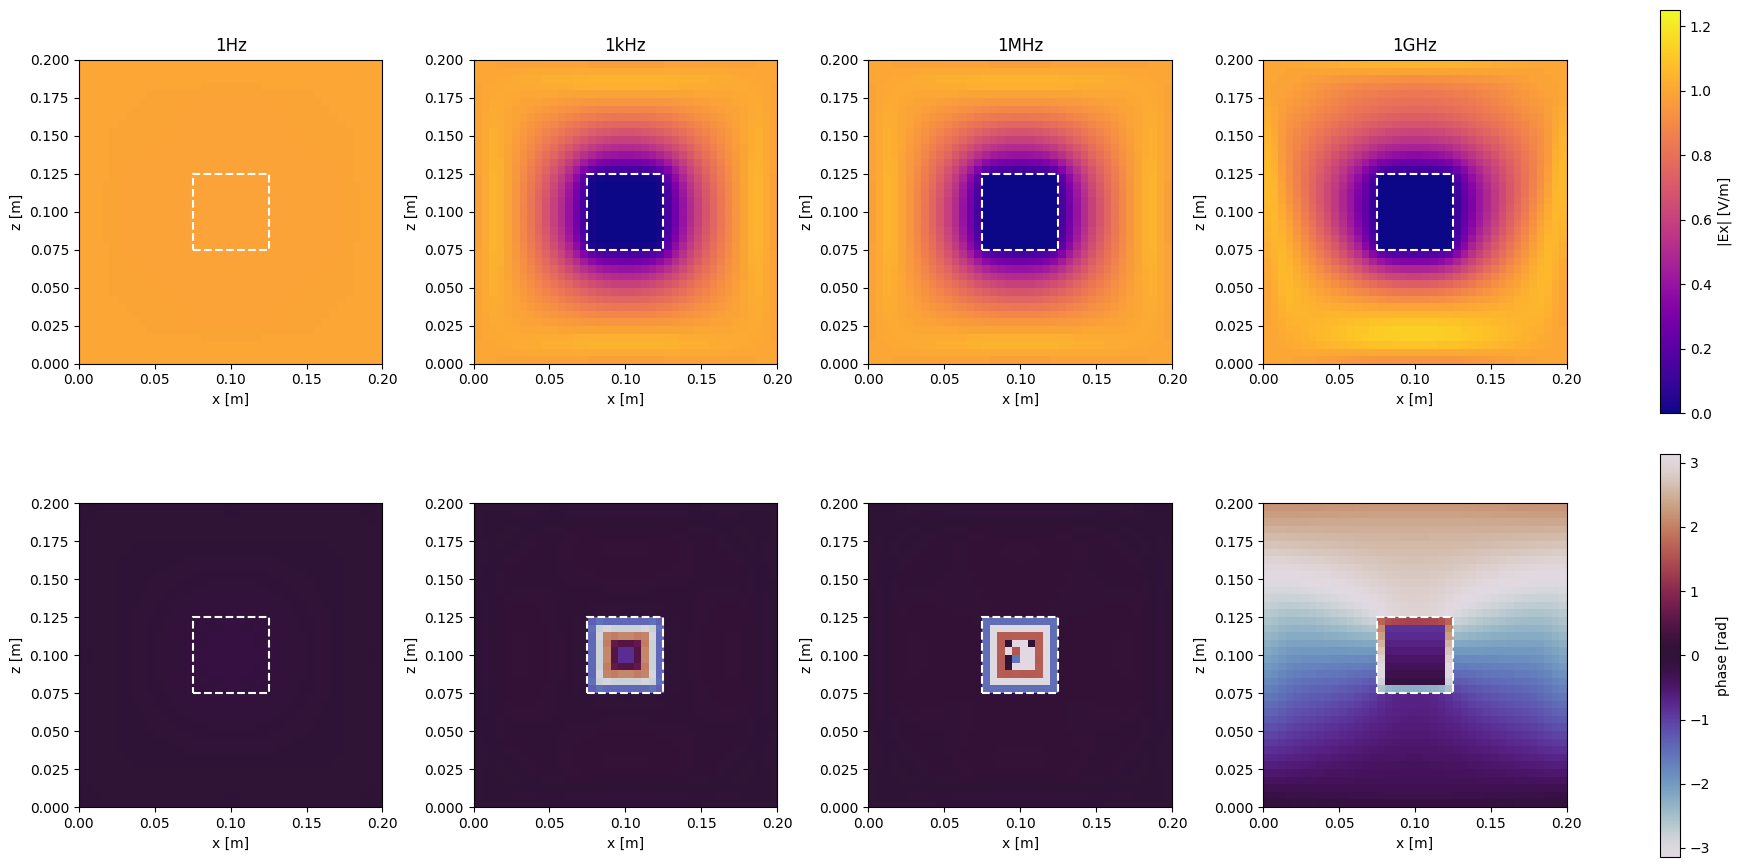

In [6]:
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(2, 4, figsize=(24, 11))
fig.subplots_adjust(wspace=0.3, hspace=0.1)
for i, (E_n, title) in enumerate(zip(E, ['1Hz', '1kHz', '1MHz', '1GHz'])):
    E_slice = E_n[:, mid, :].T

    im_mag = axes[0, i].imshow(np.abs(E_slice), origin="lower", extent=[0, domain.length, 0, domain.length], aspect="equal", vmin=0, vmax=1.25*wave.amplitude, cmap='plasma')
    im_phase = axes[1, i].imshow(np.angle(E_slice), origin="lower", extent=[0, domain.length, 0, domain.length], aspect="equal", vmin=-np.pi, vmax=np.pi, cmap='twilight')

    center = domain.length / 2
    half = 0.05 / 2

    for ax in axes[:, i]:
        rect = Rectangle((center - half, center - half), 0.05, 0.05, fill=False, edgecolor='white', linestyle='--', linewidth=1.5)
        ax.add_patch(rect)
        ax.set_xlabel("x [m]")
        ax.set_ylabel("z [m]")

    axes[0, i].set_title(f"{title}")

fig.colorbar(im_mag, ax=axes[0, :], label="|Ex| [V/m]")
fig.colorbar(im_phase, ax=axes[1, :], label="phase [rad]")

plt.show()